# Data Skills - Week 11 - Relational databases in Python

**Name:** Hannah Grushon

## How to answer

As in Part 1, run each cell in order and read the comments. When a question asks for code, add it to the cell marked `YOUR TURN` (the code is given in the question). When a question asks for an explanation, write it after **Answer:** in the Markdown cell, in your own words.

In Part 1 you used `dbplyr` to write SQL for you. Here you'll write SQL yourself and send it to DuckDB from Python. The results come back as pandas data frames.

## Setup

You need the conda environment from the lab slides (`dataskills-w11`, with `python-duckdb`, `pandas`, `matplotlib`, and `jupyterlab`). This notebook should be in your project's `code/` folder and the four CSV files in `data/`, so the paths below start with `../data/`.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# An in-memory database: it disappears when you close the notebook.
# Part 1 saved a database file instead; here we build the tables straight from the CSV files.
con = duckdb.connect()

for table in ["sites", "species", "observers", "observations"]:
    con.sql(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM read_csv('../data/{table}.csv')")

con.sql("SHOW TABLES")

Matplotlib is building the font cache; this may take a moment.


nameVARCHAR
observations
observers
sites
species


`CREATE TABLE ... AS SELECT * FROM read_csv(...)` is SQL: DuckDB reads the CSV itself, so the data never pass through pandas. `con.sql()` runs a query and prints a preview. Add `.df()` to get the result as a pandas data frame.

`DESCRIBE` shows each column and the type DuckDB chose for it:

In [2]:
con.sql("DESCRIBE observations")

column_nameVARCHAR,column_typeVARCHAR,nullVARCHAR,keyVARCHAR,defaultVARCHAR,extraVARCHAR
obs_id,BIGINT,YES,NULL,NULL,NULL
site_id,BIGINT,YES,NULL,NULL,NULL
species_id,BIGINT,YES,NULL,NULL,NULL
observer_id,BIGINT,YES,NULL,NULL,NULL
date,DATE,YES,NULL,NULL,NULL
count,BIGINT,YES,NULL,NULL,NULL


## 1. Filter and sort

This query lists the woodpeckers (family Picidae) in the `species` table:

In [3]:
con.sql("""
    SELECT code, common_name, scientific_name
    FROM species
    WHERE family = 'Picidae'
""")

codeVARCHAR,common_nameVARCHAR,scientific_nameVARCHAR
RHWO,Red-headed Woodpecker,Melanerpes erythrocephalus
DOWO,Downy Woodpecker,Dryobates pubescens


**Q1.** In the `YOUR TURN` cell, copy the query and change it to list the species in the family Cardinalidae, sorted by common name. Change the `WHERE` line to `WHERE family = 'Cardinalidae'` and add the line `ORDER BY common_name` at the end. How many species are in that family in this table? Note that SQL text values use single quotes and are case-sensitive: what does `WHERE family = 'cardinalidae'` return?

In [4]:
con.sql("""
    SELECT code, common_name, scientific_name
    FROM species
    WHERE family = 'Cardinalidae'
    ORDER BY common_name
""")

codeVARCHAR,common_nameVARCHAR,scientific_nameVARCHAR
DICK,Dickcissel,Spiza americana
INBU,Indigo Bunting,Passerina cyanea
NOCA,Northern Cardinal,Cardinalis cardinalis


In [5]:
con.sql("""
    SELECT code, common_name, scientific_name
    FROM species
    WHERE family = 'cardinalidae'
    ORDER BY common_name
""")

codeVARCHAR,common_nameVARCHAR,scientific_nameVARCHAR


**Answer:** There are three species belonging to Cardinalidae in this table. The lowercase version returned 0 species.

## 2. Summarize by month and plot

This query joins `observations` to `species`, keeps one species (Dickcissel, code `DICK`), and totals the birds counted in each month. `month(date)` pulls the month number out of a date. We use `.df()` to get a pandas data frame we can plot.

In [11]:
monthly = con.sql("""
    SELECT month(o.date) AS month, SUM(o.count) AS total
    FROM observations o
    JOIN species sp ON o.species_id = sp.species_id
    WHERE sp.code = 'DICK'
    GROUP BY month
    ORDER BY month
""").df()

monthly

,month,total
0,5,14.0
1,6,29.0
2,7,20.0
3,8,8.0


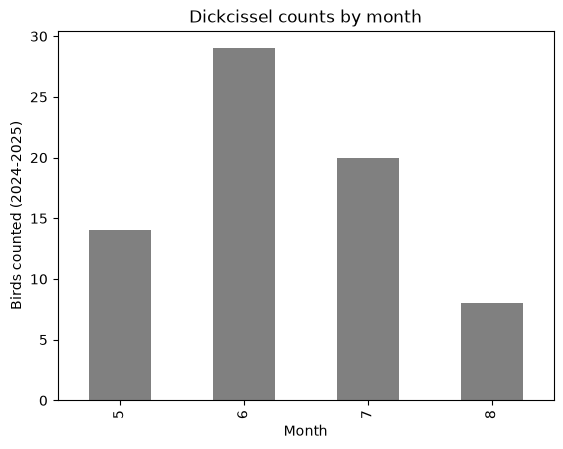

In [12]:
ax = monthly.plot.bar(x="month", y="total", legend=False, color="gray")
ax.set_xlabel("Month")
ax.set_ylabel("Birds counted (2024-2025)")
ax.set_title("Dickcissel counts by month")
plt.show()

**Q2.** In the `YOUR TURN` cell, copy the query and the plot code and change them to Sedge Wren (code `SEWR`); update the title too. In which months were Sedge Wrens counted, and when was the total highest? Some months are missing from the tables (April for Dickcissel; April and May for Sedge Wren). Why? What would you need to do to show those months as zero?

In [13]:
monthly02 = con.sql("""
    SELECT month(o.date) AS month, SUM(o.count) AS total
    FROM observations o
    JOIN species sp ON o.species_id = sp.species_id
    WHERE sp.code = 'SEWR'
    GROUP BY month
    ORDER BY month
""").df()

monthly02

,month,total
0,6,15.0
1,7,35.0
2,8,24.0
3,9,15.0


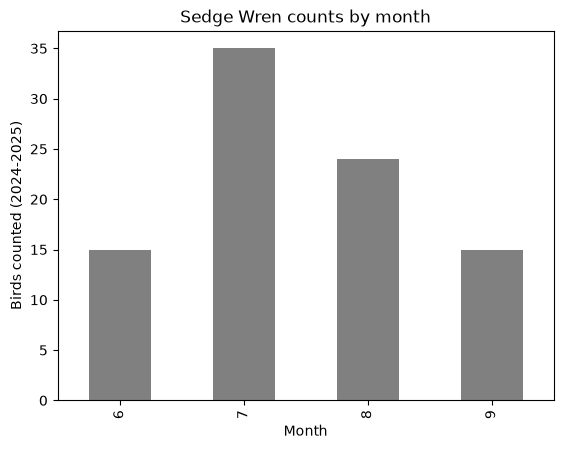

In [15]:
ax = monthly02.plot.bar(x="month", y="total", legend=False, color="gray")
ax.set_xlabel("Month")
ax.set_ylabel("Birds counted (2024-2025)")
ax.set_title("Sedge Wren counts by month")
plt.show()

**Answer:** Sedge Wrens were detected in June-September. Some months are missing from the tables because 0 Dickcissels or Sedge Wrens were detected during those months. To show them as zero, I would create a list of all months and perform a left-join with the 'observations' table, filling in missing values with zeroes.

## 3. Query a file without loading it

DuckDB can run SQL on a CSV file directly, without creating a table first. It reads only what the query needs, which is how you can work with files that are too big to open in pandas.

In [16]:
con.sql("""
    SELECT COUNT(*) AS n_rows, MIN(date) AS first_date, MAX(date) AS last_date
    FROM read_csv('../data/observations.csv')
""")

n_rowsBIGINT,first_dateDATE,last_dateDATE
480,2024-04-03,2025-09-21


**Q3.** How many rows does `observations.csv` have, and what date range does it cover? Give one situation in your own field where querying a file this way would be better than reading it into a pandas data frame with `pd.read_csv()`.

**Answer:** The CSV has 480 rows and it covers April 3rd, 2024 - September 21st, 2025. This would be useful if I had a very large vegetation survey dataset with millions of rows and I didn't want to load the full dataset.

## 4. Write your own query

**Q4.** Write a query that answers: *In 2025, which observer counted the most birds in total at the prairie and farmland sites?* Return one row per observer with the observer's name and the total, largest first. Use this outline:

- `SELECT` the observer name and `SUM(o.count) AS total`
- `FROM observations o`, joined to `sites s` (on `site_id`) and to `observers ob` (on `observer_id`)
- `WHERE s.habitat IN ('prairie', 'farmland') AND o.date >= '2025-01-01'`
- `GROUP BY` the observer name, then `ORDER BY total DESC`

Who counted the most birds, and what was the total? Why do you need two joins for this question?

**Hints:** See the *SQL queries – joins* and *Notes on SQL syntax* slides from lecture (clause order matters). The Q2 query shows the join syntax.

In [17]:
con.sql("""
SELECT ob.observer_name, SUM(o.count) AS total
FROM observations o
JOIN sites s ON o.site_id = s.site_id
JOIN observers ob ON o.observer_id = ob.observer_id
WHERE s.habitat IN ('prairie', 'farmland') AND o.date >= '2025-01-01'
GROUP BY observer_name
ORDER BY total DESC
""")

observer_nameVARCHAR,totalHUGEINT
Alexa,286
Holly,172
Matthew,144
Katrina,117


**Answer:** Alexa detected the most birds (n = 286). We need two joins because we're pulling from three different tables (sites, observations, and observers).

In [ ]:
# Close the connection when you're done
con.close()

## Submission

1. Fill in your name at the top.
2. Restart the kernel and run all cells (*Kernel > Restart Kernel and Run All Cells*), then export to HTML (*File > Save and Export Notebook As > HTML*). Don't check "Sanitize HTML".
3. Commit and push this notebook and the HTML to your `dataskills-w11-LASTNAME` repository.
4. Upload this `.ipynb` file and the HTML file to Canvas.